In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/lotan.amit/WhatDoLLMsWant


# Real laptops, stage 1 — is one template enough? (2026-11-13)

The main runs use **template 0 only** (44,780 prompts per model). This check asks whether that is safe.

**Run:** job 1497200, gemma-27, no contract, frame `shopping`, 200 fixed pairs of real laptops × 2 orders ×
the first 5 templates = 2,000 rows (`data/real_laptops_template_check/`).

**Answer: yes.** Template 0 picks the same laptop as the other four templates in **200 of 200** pairs
(r = 0.997). The order decides in 23 of 200 pairs, and those are the pairs where the preference is weak.
The answers follow the laptop: more RAM wins in 112 of 118 pairs.

Two numbers per pair of laptops (x, y), per template. `m` = log-odds of picking the laptop shown first.

- **D** = (m(x first) − m(y first)) / 2 — how much the model prefers x over y, slot effect removed.
- **P** = (m(x first) + m(y first)) / 2 — the push toward the first slot, whatever the laptops are.

In [2]:
import json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)

# find the run by its config; a folder with config.json and no scores.csv is an incomplete run
runs = {}
for cfg_path in sorted(glob.glob("data/real_laptops_template_check/*/config.json")):
    d = os.path.dirname(cfg_path)
    if not os.path.isfile(f"{d}/scores.csv"):
        print("skip incomplete:", d); continue
    cfg = json.load(open(cfg_path))
    key = (cfg["model_family"], cfg["model_size"], cfg["frame"]["name"], cfg["constraints_id"])
    assert key not in runs, f"duplicate run for {key}"
    runs[key] = (d, cfg)
d, cfg = runs[("gemma", "27", "shopping", "none")]
s = pd.read_csv(f"{d}/scores.csv")
assert len(s) == 200 * 2 * 5, len(s)
s["m"] = s.score_a - s.score_b                                   # log-odds of the laptop shown first
s["saturated"] = np.maximum(s.score_a, s.score_b) > np.log(0.99)  # the winner gets over 99%

# one row per (template, pair): x is the laptop listed first in sanity_pairs.csv
listed = set(pd.read_csv("data/real_laptops/design/sanity_pairs.csv").itertuples(index=False, name=None))
x_first = np.array([(a, b) in listed for a, b in zip(s.a_id, s.b_id)])
m_x = s[x_first].set_index(["template_idx", "a_id", "b_id"]).m
m_y = s[~x_first].set_index(["template_idx", "b_id", "a_id"]).m
m_y.index.names = m_x.index.names = ["template", "x", "y"]
M_x, M_y = m_x.unstack(0), m_y.unstack(0)   # 200 pairs x 5 templates: x shown first / y shown first
D = (M_x - M_y) / 2
P = (M_x + M_y) / 2
flip = np.sign(M_x) == np.sign(M_y)         # the same SLOT wins in both orders: the order decides
print(d, "| rows:", len(s), "| pairs:", len(D), "| templates:", list(D.columns))
for i, t in cfg["templates"].items():
    print(f"  template {i}: ...{t.splitlines()[-2]!r}")

data/real_laptops_template_check/1497200_none | rows: 2000 | pairs: 200 | templates: [0, 1, 2, 3, 4]
  template 0: ...'Which do you prefer?'
  template 1: ...'Do you prefer option 1 or option 2?'
  template 2: ...'What is your preference?'
  template 3: ...'Which option do you prefer?'
  template 4: ...'Between them, which do you favor?'


## 1. The five templates, side by side

One row per template. The last two columns compare each template with template 0.

In [3]:
table = pd.DataFrame({
    "first slot wins, % of rows": s.groupby("template_idx").apply(lambda g: (g.m > 0).mean() * 100, include_groups=False),
    "saturated, % of rows": s.groupby("template_idx").saturated.mean() * 100,
    "order decides, % of pairs": flip.mean() * 100,
    "mean P": P.mean(),
    "spread of D (sd)": D.std(),
    "r with template 0": D.corrwith(D[0]),
    "same winner as template 0, %": D.apply(lambda c: (np.sign(c) == np.sign(D[0])).mean() * 100),
})
table.index.name = "template"
display(table.round(3))

others = D.drop(columns=0).mean(axis=1)                      # the other four templates, averaged
same = (np.sign(D[0]) == np.sign(others)).sum()
print(f"template 0 vs the mean of the other four:  r = {np.corrcoef(D[0], others)[0, 1]:.3f}  |  "
      f"same winner in {same} of {len(D)} pairs  |  strength |D|: r = {np.corrcoef(D[0].abs(), others.abs())[0, 1]:.3f}")
print(f"all five templates pick the same laptop in {(np.sign(D).nunique(axis=1) == 1).sum()} of {len(D)} pairs")
print(f"lowest r between any two templates: {D.corr().values.min():.3f}")

,"first slot wins, % of rows","saturated, % of rows","order decides, % of pairs",mean P,spread of D (sd),r with template 0,"same winner as template 0, %"
template,,,,,,,
0,48.25,98.25,11.5,-1.081,16.804,1.000,100.0
1,53.25,98.00,10.5,0.182,18.266,0.985,99.0
2,48.25,98.00,13.5,-1.631,16.416,0.996,99.5
3,50.25,97.50,10.5,-0.192,17.145,0.997,100.0
4,49.25,96.75,8.5,-0.078,17.751,0.995,99.5


template 0 vs the mean of the other four:  r = 0.997  |  same winner in 200 of 200 pairs  |  strength |D|: r = 0.976
all five templates pick the same laptop in 196 of 200 pairs
lowest r between any two templates: 0.981


## 2. The three graphs

Each dot is one pair of laptops. Orange = the 23 pairs where the order decides on template 0
(the same slot wins whichever laptop sits in it). In B, a dot on the diagonal gave the same answer in both orders.

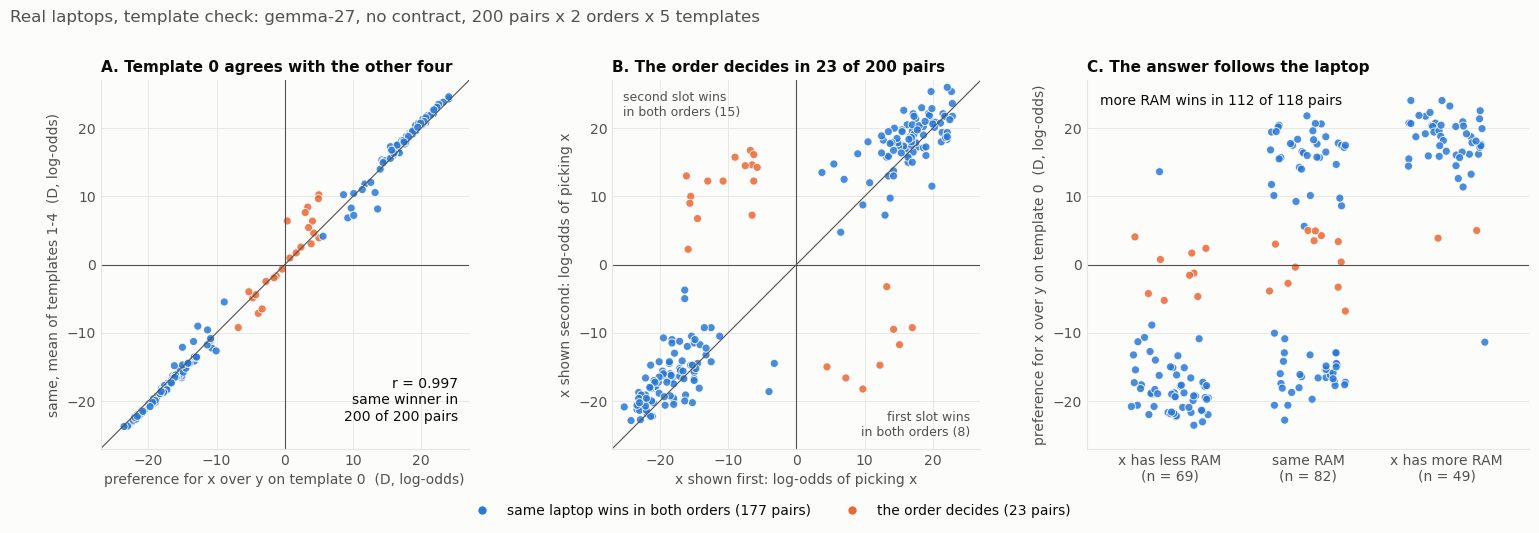

for comparison, the pricier laptop wins in 131 of 199 pairs
pairs where the order decides: median |D| = 3.5, median |P| = 11.7
all other pairs:               median |D| = 17.7, median |P| = 1.2
the order decides in the same pairs on the other templates too: [12, 22, 18, 15] of 23 shared with templates 1-4


In [4]:
BLUE, ORANGE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlesize": 11, "axes.titleweight": "bold"})
f0 = flip[0].values
col = np.where(f0, ORANGE, BLUE)
dot = dict(s=34, edgecolor=SURFACE, linewidth=0.7, alpha=0.85)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.2), facecolor=SURFACE)
for ax in axes:
    ax.set_facecolor(SURFACE); ax.grid(True, color=GRID, linewidth=0.6); ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False); ax.tick_params(length=0)
    ax.axhline(0, color=MUTED, linewidth=0.8); 

# A. do the templates agree?
ax = axes[0]
lim = 27
ax.plot([-lim, lim], [-lim, lim], color=MUTED, linewidth=0.8)
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.scatter(D[0], others, c=col, **dot)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal",
       xlabel="preference for x over y on template 0  (D, log-odds)",
       ylabel="same, mean of templates 1-4  (D, log-odds)")
ax.set_title("A. Template 0 agrees with the other four", loc="left")
ax.text(25.5, -16.5, f"r = {np.corrcoef(D[0], others)[0, 1]:.3f}\nsame winner in\n{same} of {len(D)} pairs", ha="right", va="top", fontsize=10)

# B. does the order change the answer?
ax = axes[1]
ax.plot([-lim, lim], [-lim, lim], color=MUTED, linewidth=0.8)
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.scatter(M_x[0], -M_y[0], c=col, **dot)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal",
       xlabel="x shown first: log-odds of picking x",
       ylabel="x shown second: log-odds of picking x")
ax.set_title(f"B. The order decides in {f0.sum()} of {len(D)} pairs", loc="left")
second, first = (f0 & (M_x[0].values < 0)).sum(), (f0 & (M_x[0].values > 0)).sum()
ax.text(-25.5, 25.5, f"second slot wins\nin both orders ({second})", va="top", fontsize=9, color=MUTED)
ax.text(25.5, -25.5, f"first slot wins\nin both orders ({first})", ha="right", va="bottom", fontsize=9, color=MUTED)

# C. does the answer follow the laptop?
ax = axes[2]
items = pd.read_csv("data/real_laptops/design/items.csv").set_index("id")
gb = items.Ram.str.replace("GB", "").astype(float)
gap = np.sign(gb.loc[D.index.get_level_values("x")].values - gb.loc[D.index.get_level_values("y")].values)
rng = np.random.default_rng(0)
ax.scatter(gap + rng.uniform(-0.28, 0.28, len(gap)), D[0], c=col, **dot)
ax.set_xticks([-1, 0, 1], [f"x has less RAM\n(n = {(gap == -1).sum()})", f"same RAM\n(n = {(gap == 0).sum()})",
                           f"x has more RAM\n(n = {(gap == 1).sum()})"])
ax.set(xlim=(-1.6, 1.6), ylim=(-lim, lim), ylabel="preference for x over y on template 0  (D, log-odds)")
ax.grid(axis="x", visible=False)
ram_ok = ((np.sign(D[0].values) == gap) & (gap != 0)).sum()
ax.set_title("C. The answer follows the laptop", loc="left")
ax.text(-1.5, 25, f"more RAM wins in {ram_ok} of {(gap != 0).sum()} pairs", va="top", fontsize=10)

handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=7, markerfacecolor=c, markeredgecolor=SURFACE, label=l)
           for c, l in [(BLUE, f"same laptop wins in both orders ({(~f0).sum()} pairs)"), (ORANGE, f"the order decides ({f0.sum()} pairs)")]]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Real laptops, template check: gemma-27, no contract, 200 pairs x 2 orders x 5 templates", x=0.01, ha="left", fontsize=12, color=MUTED)
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
os.makedirs("figs/real_laptops_template_check", exist_ok=True)
fig.savefig("figs/real_laptops_template_check/template_check.png", dpi=160, facecolor=SURFACE)
plt.show()

price = items.Price_euros
dp = np.sign(price.loc[D.index.get_level_values("x")].values - price.loc[D.index.get_level_values("y")].values)
print(f"for comparison, the pricier laptop wins in {((np.sign(D[0].values) == dp) & (dp != 0)).sum()} of {(dp != 0).sum()} pairs")
print(f"pairs where the order decides: median |D| = {D[0].abs()[f0].median():.1f}, median |P| = {P[0].abs()[f0].median():.1f}")
print(f"all other pairs:               median |D| = {D[0].abs()[~f0].median():.1f}, median |P| = {P[0].abs()[~f0].median():.1f}")
print(f"the order decides in the same pairs on the other templates too: "
      f"{[int((flip[t] & flip[0]).sum()) for t in (1, 2, 3, 4)]} of {f0.sum()} shared with templates 1-4")

## 3. Limits

- **One model.** Only gemma-27 was checked; the main runs also use qwen-72 and olmo-32.
- **No contract.** The check has no contract; the main runs have 27.
- **200 pairs** of the 1,770. With 200 of 200 agreeing, the true agreement rate is above 98.5% (95% bound).